# Étude G2 — Seuil de déclenchement

**Question G2 :** pour chaque niveau de la Météo des forêts, quelle part des jours a eu au moins un départ de feu dans le 77 ?

**Indicateur (fiche G2) :** taux de jours d'alerte sans feu = jours de niveau ≥ N sans feu / jours de niveau ≥ N.
**Garde-fou :** taux de feux partis les jours de niveau < N.

Règles déjà décidées :
- un départ de feu = une fiche BDIFF (décision 006) ;
- on utilise `niveau_j1`, la prévision faite la veille pour le lendemain (fiche G2) ;
- comparaison limitée à l'Île-de-France (décision 007).

Sources : `data/bronze/` (voir `data/bronze/SOURCES.md`).

## 1. Chargement

In [1]:
from pathlib import Path 
import pandas as pd
import matplotlib.pyplot as plt

BRONZE = Path('..') / 'data' / 'bronze'
DEP_IDF = ['75', '77', '78', '91', '92', '93', '94', '95']
DEP_BSPP = ['75', '92', '93', '94']   # nombre de feux inconnu dans la BDIFF (décision 007)

### Météo des forêts

Le format change chaque année : séparateur `,` ou `;`, colonne `nom_dep` ou `dep_nom`. On lit chaque fichier tel quel, puis on harmonise les noms de colonnes.

In [2]:
fichiers_mdf = {
    2024: ',',
    2025: ',',
    2026: ';',
}

morceaux = []
for annee, sep in fichiers_mdf.items():
    df = pd.read_csv(BRONZE / 'meteo_des_forets' / f'mdf_{annee}.csv', sep=sep, dtype=str)
    df = df.rename(columns={'dep_nom': 'nom_dep'})
    df['annee_fichier'] = annee
    print(annee, df.shape, list(df.columns))
    morceaux.append(df)

mdf = pd.concat(morceaux, ignore_index=True)
mdf.head()

2024 (11520, 6) ['date', 'num_dep', 'niveau_j1', 'niveau_j2', 'nom_dep', 'annee_fichier']
2025 (11520, 6) ['date', 'num_dep', 'niveau_j1', 'niveau_j2', 'nom_dep', 'annee_fichier']
2026 (12576, 6) ['date', 'num_dep', 'niveau_j1', 'niveau_j2', 'nom_dep', 'annee_fichier']


,date,num_dep,niveau_j1,niveau_j2,nom_dep,annee_fichier
0,2024-06-04T16:00:00Z,1,1,1,Ain,2024
1,2024-06-04T16:00:00Z,2,1,1,Aisne,2024
2,2024-06-04T16:00:00Z,3,1,1,Allier,2024
3,2024-06-04T16:00:00Z,4,1,1,Alpes-de-Haute-Provence,2024
4,2024-06-04T16:00:00Z,5,1,1,Hautes-Alpes,2024


On met tout au même format :
- `date_publication` : la date est en UTC, on la passe en heure française ;
- `code_departement` : sur 2 caractères (`1` devient `01`, `2A` ne change pas) ;
- les niveaux en nombres entiers.

In [3]:
mdf['date_publication'] = pd.to_datetime(mdf['date'], utc=True).dt.tz_convert('Europe/Paris')
mdf['code_departement'] = mdf['num_dep'].str.strip().str.zfill(2)
mdf['niveau_j1'] = mdf['niveau_j1'].astype(int)
mdf['niveau_j2'] = mdf['niveau_j2'].astype(int)

mdf[['date', 'date_publication', 'num_dep', 'code_departement', 'niveau_j1']].head()

,date,date_publication,num_dep,code_departement,niveau_j1
0,2024-06-04T16:00:00Z,2024-06-04 18:00:00+02:00,1,01,1
1,2024-06-04T16:00:00Z,2024-06-04 18:00:00+02:00,2,02,1
2,2024-06-04T16:00:00Z,2024-06-04 18:00:00+02:00,3,03,1
3,2024-06-04T16:00:00Z,2024-06-04 18:00:00+02:00,4,04,1
4,2024-06-04T16:00:00Z,2024-06-04 18:00:00+02:00,5,05,1


### BDIFF

Un seul export : `Incendies_2016_2025.csv`, zone Île-de-France, du 01/01/2016 au 31/12/2025.
Il y a **3 lignes d'information** avant l'en-tête (le nombre change selon l'export) : on cherche la ligne qui commence par `Année;`.

In [4]:
def lire_bdiff(chemin):
    lignes = chemin.read_text(encoding='utf-8-sig').splitlines()
    entete = next(n for n, l in enumerate(lignes) if l.startswith('Année;'))
    return pd.read_csv(chemin, sep=';', skiprows=entete, dtype=str)

bdiff = lire_bdiff(BRONZE / 'bdiff' / 'Incendies_2016_2025.csv')
bdiff['date_alerte'] = pd.to_datetime(bdiff['Date de première alerte'])
bdiff['jour'] = bdiff['date_alerte'].dt.date
print('feux 2016-2025 :', len(bdiff))

# Pour croiser avec l'indice, seules 2024 et 2025 comptent :
# la Météo des forêts commence en 2024, et la BDIFF 2026 n'est pas encore publiée.
bdiff_croise = bdiff[bdiff['Année'].isin(['2024', '2025'])]
bdiff[['Année', 'Numéro', 'Département', 'Nom de la commune', 'Date de première alerte', 'Surface parcourue (m2)', 'Nature']].head()

feux 2016-2025 : 291


,Année,Numéro,Département,Nom de la commune,Date de première alerte,Surface parcourue (m2),Nature
0,2016,688,77,Fontainebleau,2016-03-22 14:43:00,60,NaN
1,2016,689,77,Fontainebleau,2016-04-20 15:02:00,10,NaN
2,2016,690,77,Perthes,2016-04-29 17:38:00,20,NaN
3,2016,691,77,Fontainebleau,2016-05-04 13:25:00,10000,NaN
4,2016,692,77,Fontainebleau,2016-07-08 15:35:00,2000,NaN


## 2. Contrôles avant de croiser

In [5]:
# Un seul niveau par jour et par département ?
mdf['jour_publication'] = mdf['date_publication'].dt.date
doublons = mdf.duplicated(['jour_publication', 'code_departement']).sum()
print('Doublons (jour, département) dans la Météo des forêts :', doublons)

# Combien de jours par saison, et de quand à quand ?
mdf.groupby('annee_fichier')['jour_publication'].agg(['min', 'max', 'nunique'])

Doublons (jour, département) dans la Météo des forêts : 0


,min,max,nunique
annee_fichier,,,
2024,2024-06-03,2024-09-30,120
2025,2025-06-03,2025-09-30,120
2026,2026-05-28,2026-10-05,131


In [6]:
# Doublons dans la BDIFF (Année + Numéro identifie un feu)
print('Doublons BDIFF :', bdiff.duplicated(['Année', 'Numéro']).sum())

# Feux par département et par année
pd.crosstab(bdiff['Département'], bdiff['Année'], margins=True)

Doublons BDIFF : 0


Année,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,All
Département,,,,,,,,,,,
77,13,10,7,12,62,29,35,18,10,55,251
78,0,0,0,0,0,0,1,0,1,2,4
91,0,0,0,0,5,0,10,17,0,3,35
95,0,0,0,0,0,0,1,0,0,0,1
All,13,10,7,12,67,29,47,35,11,60,291


In [7]:
# Valeurs manquantes dans les colonnes utiles
bdiff[['Date de première alerte', 'Département', 'Code INSEE', 'Nature']].isna().sum()

Date de première alerte      0
Département                  0
Code INSEE                   0
Nature                     166
dtype: int64

## 3. Le jour concerné par le niveau

La Météo des forêts est publiée la veille : `niveau_j1` vaut pour **le lendemain** de la publication. C'est ce jour-là qu'on rapproche des feux.

⚠️ Déduit de la documentation (publication à 17 h pour J+1 et J+2), pas écrit noir sur blanc : à confirmer.

In [8]:
mdf['date_concernee'] = (mdf['date_publication'].dt.normalize() + pd.Timedelta(days=1)).dt.date
mdf.groupby('annee_fichier')['date_concernee'].agg(['min', 'max'])

,min,max
annee_fichier,,
2024,2024-06-04,2024-10-01
2025,2025-06-04,2025-10-01
2026,2026-05-29,2026-10-06


## 4. La table « un jour × un département » (Île-de-France)

C'est la table dont G2 a besoin. Pour chaque jour et chaque département : le niveau, le nombre de feux, et s'il y a eu au moins un feu.

On s'arrête à 2024-2025 : la BDIFF 2026 n'est pas encore publiée.

In [9]:
feux_par_jour = (bdiff.groupby(['jour', 'Département']).size()
                 .rename('nb_feux').reset_index()
                 .rename(columns={'jour': 'date_concernee', 'Département': 'code_departement'}))

jours = mdf[mdf['code_departement'].isin(DEP_IDF) & mdf['annee_fichier'].isin([2024, 2025])]
jours = jours[['date_concernee', 'code_departement', 'nom_dep', 'niveau_j1', 'date_publication']]

table = jours.merge(feux_par_jour, on=['date_concernee', 'code_departement'], how='left')

# Pas de feu ce jour-là : 0. Sauf pour la BSPP, où on ne sait pas : on laisse vide.
table['nb_feux'] = table['nb_feux'].fillna(0)
table.loc[table['code_departement'].isin(DEP_BSPP), 'nb_feux'] = pd.NA
table['nb_feux'] = table['nb_feux'].astype('Int64')
table['jour_avec_feu'] = (table['nb_feux'] > 0).astype('boolean')

print(table.shape)
table.sort_values(['date_concernee', 'code_departement']).head(10)

(1920, 7)


,date_concernee,code_departement,nom_dep,niveau_j1,date_publication,nb_feux,jour_avec_feu
952,2024-06-04,75,Paris,1,2024-06-03 18:00:00+02:00,<NA>,<NA>
953,2024-06-04,77,Seine-et-Marne,1,2024-06-03 18:00:00+02:00,0,False
954,2024-06-04,78,Yvelines,1,2024-06-03 18:00:00+02:00,0,False
955,2024-06-04,91,Essonne,1,2024-06-03 18:00:00+02:00,0,False
956,2024-06-04,92,Hauts-de-Seine,1,2024-06-03 18:00:00+02:00,<NA>,<NA>
957,2024-06-04,93,Seine-Saint-Denis,1,2024-06-03 18:00:00+02:00,<NA>,<NA>
958,2024-06-04,94,Val-de-Marne,1,2024-06-03 18:00:00+02:00,<NA>,<NA>
959,2024-06-04,95,Val-d'Oise,1,2024-06-03 18:00:00+02:00,0,False
0,2024-06-05,75,Paris,1,2024-06-04 18:00:00+02:00,<NA>,<NA>
1,2024-06-05,77,Seine-et-Marne,1,2024-06-04 18:00:00+02:00,0,False


In [10]:
# Contrôle : aucun feu ne doit disparaître sans explication pendant la jointure (années croisées : 2024-2025)
t77 = table[table['code_departement'] == '77']   # la table du 77, utilisée dans la suite

f77_total = int((bdiff_croise['Département'] == '77').sum())
f77_rattaches = int(t77['nb_feux'].sum())
jours_saison = set(t77['date_concernee'])
f77_hors_saison = int(((bdiff_croise['Département'] == '77') & ~bdiff_croise['jour'].isin(jours_saison)).sum())

controle = pd.DataFrame({'feux du 77': [f77_total, f77_rattaches, f77_hors_saison]},
                        index=['dans la BDIFF (2024-2025, toute l\'année)',
                               'rattachés à un jour de la saison de l\'indice',
                               'hors saison (pas de niveau ce jour-là)'])
print('Contrôle :', 'OK, tout est expliqué' if f77_rattaches + f77_hors_saison == f77_total else 'ÉCART NON EXPLIQUÉ')
controle

Contrôle : OK, tout est expliqué


,feux du 77
"dans la BDIFF (2024-2025, toute l'année)",65
rattachés à un jour de la saison de l'indice,36
hors saison (pas de niveau ce jour-là),29


## 5. Pour chaque niveau, quelle part des jours a eu un feu ? (Seine-et-Marne)

In [11]:
par_niveau = (t77.groupby('niveau_j1')
              .agg(jours=('date_concernee', 'size'),
                   jours_avec_feu=('jour_avec_feu', 'sum'),
                   feux=('nb_feux', 'sum')))
par_niveau['part_jours_avec_feu_%'] = (100 * par_niveau['jours_avec_feu'] / par_niveau['jours']).round(1)
par_niveau

,jours,jours_avec_feu,feux,part_jours_avec_feu_%
niveau_j1,,,,
1,218,24,26,11.0
2,21,6,10,28.6
3,1,0,0,0.0


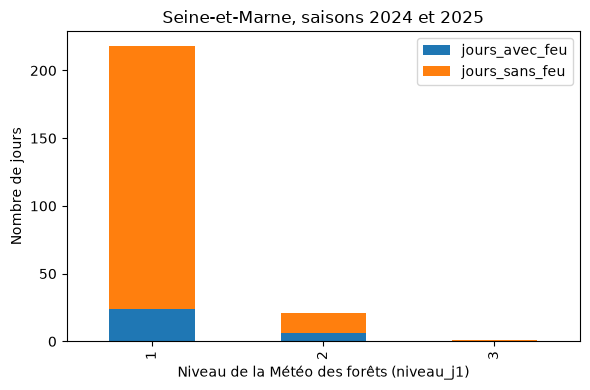

In [12]:
ax = par_niveau[['jours_avec_feu']].assign(
        jours_sans_feu=par_niveau['jours'] - par_niveau['jours_avec_feu']
     ).plot(kind='bar', stacked=True, figsize=(6, 4))
ax.set_xlabel('Niveau de la Météo des forêts (niveau_j1)')
ax.set_ylabel('Nombre de jours')
ax.set_title('Seine-et-Marne, saisons 2024 et 2025')
plt.tight_layout()

## 6. L'indicateur G2 et son garde-fou, pour chaque valeur de N

In [13]:
lignes = []
feux_saison = int(t77['nb_feux'].sum())
for N in [2, 3, 4]:
    alerte = t77['niveau_j1'] >= N
    jours_alerte = int(alerte.sum())
    jours_alerte_sans_feu = int((alerte & ~t77['jour_avec_feu']).sum())
    feux_sous_seuil = int(t77.loc[~alerte, 'nb_feux'].sum())
    lignes.append({
        'N': N,
        'jours d\'alerte': jours_alerte,
        'jours d\'alerte sans feu': jours_alerte_sans_feu,
        'taux d\'alerte sans feu %': round(100 * jours_alerte_sans_feu / jours_alerte, 1) if jours_alerte else None,
        'feux les jours < N': feux_sous_seuil,
        'garde-fou : taux de feux sous le seuil %': round(100 * feux_sous_seuil / feux_saison, 1) if feux_saison else None,
    })
pd.DataFrame(lignes).set_index('N')

,jours d'alerte,jours d'alerte sans feu,taux d'alerte sans feu %,feux les jours < N,garde-fou : taux de feux sous le seuil %
N,,,,,
2,22,16,72.7,26,72.2
3,1,1,100.0,36,100.0
4,0,0,NaN,36,100.0


## 7. Les feux que l'indice ne voit pas

La Météo des forêts n'est publiée que de juin à septembre. Combien de feux du 77 partent en dehors ?

In [14]:
f77 = bdiff_croise[bdiff_croise['Département'] == '77'].copy()
dans_saison = f77['jour'].isin(set(t77['date_concernee']))
print('Feux du 77 :', len(f77), '| pendant la saison de l\'indice :', int(dans_saison.sum()), '| hors saison :', int((~dans_saison).sum()))
f77.loc[~dans_saison, 'date_alerte'].dt.month.value_counts().sort_index().rename('feux hors saison par mois')

Feux du 77 : 65 | pendant la saison de l'indice : 36 | hors saison : 29


date_alerte
1      2
4     11
5     10
6      2
10     2
11     2
Name: feux hors saison par mois, dtype: int64

## 8. Contexte : les feux du 77 de 2016 à 2025

Ces années n'ont pas d'indice, on ne peut pas les croiser. Elles servent à juger si 2024 et 2025 sont représentatives, et à mesurer la part des feux que l'indice ne peut pas voir (hors juin-septembre).

In [15]:
f77_10ans = bdiff[bdiff['Département'] == '77'].copy()
f77_10ans['mois'] = f77_10ans['date_alerte'].dt.month
par_annee = f77_10ans.groupby('Année').agg(feux=('Numéro', 'size'),
                                         feux_juin_sept=('mois', lambda m: int(m.between(6, 9).sum())))
par_annee['hors_juin_sept_%'] = (100 * (1 - par_annee['feux_juin_sept'] / par_annee['feux'])).round(0)
print('Feux du 77 sur 2016-2025 :', len(f77_10ans))
print('Moyenne 2016-2023 :', round(par_annee.loc[[str(a) for a in range(2016, 2024)], 'feux'].mean(), 1), 'feux par an')
print('Sur 10 ans, hors juin-septembre :', round(100 * (1 - f77_10ans['mois'].between(6, 9).mean())), '%')
par_annee

Feux du 77 sur 2016-2025 : 251
Moyenne 2016-2023 : 23.2 feux par an
Sur 10 ans, hors juin-septembre : 35 %


,feux,feux_juin_sept,hors_juin_sept_%
Année,,,
2016,13,9,31.0
2017,10,5,50.0
2018,7,4,43.0
2019,12,5,58.0
2020,62,53,15.0
2021,29,8,72.0
2022,35,30,14.0
2023,18,11,39.0
2024,10,6,40.0


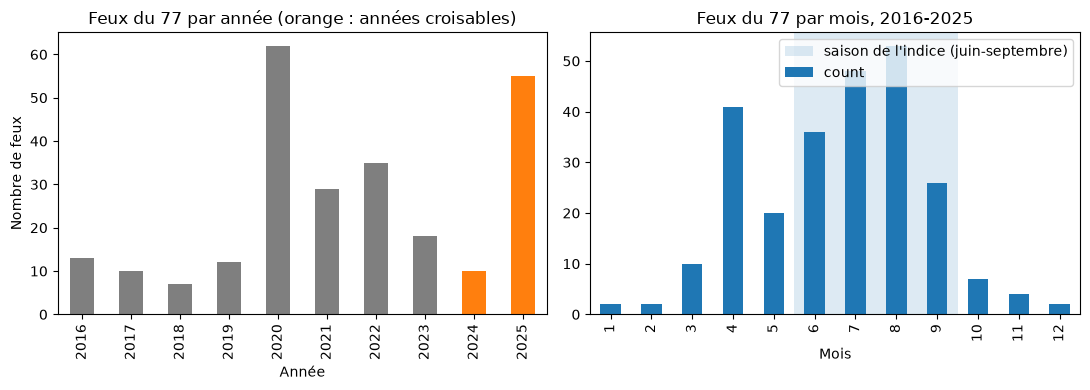

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
couleurs = ['tab:orange' if a in ('2024', '2025') else 'tab:gray' for a in par_annee.index]
par_annee['feux'].plot(kind='bar', ax=axes[0], color=couleurs)
axes[0].set_title('Feux du 77 par année (orange : années croisables)')
axes[0].set_ylabel('Nombre de feux')
f77_10ans['mois'].value_counts().reindex(range(1, 13), fill_value=0).plot(kind='bar', ax=axes[1])
axes[1].axvspan(4.5, 8.5, alpha=0.15, label='saison de l\'indice (juin-septembre)')
axes[1].set_title('Feux du 77 par mois, 2016-2025')
axes[1].set_xlabel('Mois')
axes[1].legend()
plt.tight_layout()

## 9. Ce qu'on retient

À compléter après lecture des résultats :
- …
- …

Limites à garder en tête : 2 saisons seulement, très peu de jours de niveau élevé dans le 77, rattachement niveau / jour déduit, feux de forêt seulement (décision 006).